In [3]:
import torch
import DepthEstimator
torch.__version__
from huggingface_hub import login

with open('HF_key.txt', 'r', encoding='utf-8') as file:
    content = file.read()
    login(content)

In [ ]:
H = torch.arange(10)
W = torch.arange(20)
c = torch.stack(torch.meshgrid((W,H), indexing = "xy"), -1)
c.shape
c[5,10]

In [ ]:
image = torch.randn(1,3,224,224)
grid = torch.randn(1,224,224,2) 
torch.nn.functional.grid_sample(image, grid).shape

In [ ]:
model = DepthEstimator.DepthEstimator()
model = model.eval()
model = torch.compile(model, fullgraph = True, backend = "inductor", mode = "max-autotune")

In [ ]:
with torch.inference_mode():
    model.forward(torch.randn(1,3,224,224))
    for i in range(100):
        print(i)
        model.forward(torch.randn(1,3,224,224))

In [ ]:
ims = proc(torch.randn(2,3,224,224), return_tensors = "pt", do_rescale = False)
PoseEstimator.PoseEstimator(3).forward(dino(**ims)[0])

In [4]:
import PoseEstimator
import importlib
importlib.reload(PoseEstimator)
PoseEstimator.PoseEstimator(3).forward(torch.randn(10,2,3,224,224))

Loading weights:   0%|          | 0/415 [00:00<?, ?it/s]

tensor([[-1.0319, -0.4153, -0.1569, -0.6028, -0.7872, -0.4950, -0.2269],
        [-0.9742, -0.4456, -0.1687, -0.6774, -0.7447, -0.4837, -0.3005],
        [-1.0554, -0.3621, -0.1154, -0.5711, -0.7059, -0.4738, -0.2661],
        [-1.0367, -0.4193, -0.1809, -0.6179, -0.6591, -0.4270, -0.2419],
        [-1.0694, -0.4032, -0.1898, -0.5798, -0.6682, -0.4436, -0.1851],
        [-1.0440, -0.4589, -0.1362, -0.6548, -0.6831, -0.5052, -0.3500],
        [-1.1209, -0.4149, -0.1400, -0.5604, -0.7222, -0.5112, -0.2792],
        [-1.0542, -0.4278, -0.1123, -0.5544, -0.7394, -0.5445, -0.2532],
        [-0.9849, -0.3107, -0.1679, -0.6419, -0.7715, -0.4999, -0.3135],
        [-1.0883, -0.4422, -0.0916, -0.6322, -0.6709, -0.4593, -0.2476]],
       grad_fn=<AddmmBackward0>)

In [1]:
import process_video
process_video.process_video(r"C:\Users\simon\Coding\MonoDepthEstimation\training_data\raw_mov\IMG_2743.MOV", r"C:\Users\simon\Coding\MonoDepthEstimation\training_data\proc_data\test.pt")

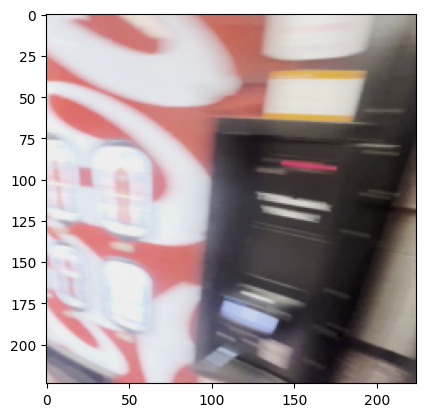

In [21]:
t = torch.load(r"C:\Users\simon\Coding\MonoDepthEstimation\training_data\proc_data\test.pt")
import matplotlib.pyplot as plt
plt.imshow(t[305].permute(1,2,0))